# LaserCut GmbH — Exploratory Data Analysis (EDA)

**Scope:** Only the assignment step: explore the already-extended dataset using suitable statistics and visualizations, investigate relationships and unusual observations.

## Questions
1. What do the feature distributions look like?
2. Are there missing or suspicious values?
3. Which features vary the most?
4. Which features appear related?
5. Which unusual parts should be inspected in their DXF drawings?

Expected feature columns: `width`, `height`, `cutting_length`, `number_of_holes`, `bounding_box_area`.

## 1. Load the dataset

Place this notebook in your project folder, or change `DATASET_PATH` to your CSV location.

In [13]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATASET_PATH = Path("customers_sales_with_bounds.csv")  # Change if needed
df = pd.read_csv(DATASET_PATH)

print(f"Dataset shape: {df.shape[0]} rows × {df.shape[1]} columns")
print("Columns:", df.columns.tolist())
display(df.head())

Dataset shape: 79 rows × 10 columns
Columns: ['customer_name', 'customer_branch', 'file_name', 'order_quantity', 'possible_duplicate', 'bounding_box_width', 'bounding_length', 'cutting_length', 'number_of_holes', 'bounding_box_area']


,customer_name,customer_branch,file_name,order_quantity,possible_duplicate,bounding_box_width,bounding_length,cutting_length,number_of_holes,bounding_box_area
0,MetalForm SA,Frankfurt Branch,Geo (1).DXF,1600,False,2110.000062,2110.000062,3438.024977,0.0,4.452100e+06
1,AutoParts AG,Munich Branch,Geo (10).DXF,9650,False,853.825891,333.401400,3646.101350,0.0,2.846667e+05
2,PrecisionCut GmbH,Stuttgart Branch,Geo (11).DXF,7800,False,164.020585,145.152365,1993.853699,0.0,2.380798e+04
3,PrecisionCut GmbH,Stuttgart Branch,Geo (15).DXF,4000,True,193.800891,138.442589,1302.774283,0.0,2.683030e+04
4,AutoParts AG,Berlin Branch,Geo (12).DXF,8800,True,937.150697,74.006665,2815.159795,9.0,6.935540e+04


## 2. Select the features


In [14]:
FEATURES = [
    "bounding_box_width",
    "bounding_length",
    "cutting_length",
    "number_of_holes",
    "bounding_box_area",
]
ID_COLUMNS = ["filename", "customer"]  # Edit to match your CSV

available_features = [c for c in FEATURES if c in df.columns]
missing_features = [c for c in FEATURES if c not in df.columns]
print("Available features:", available_features)

if not available_features:
    raise ValueError("No expected feature columns found. Edit FEATURES to match your CSV.")

for col in available_features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

numeric_df = df[available_features].copy()

Available features: ['bounding_box_width', 'bounding_length', 'cutting_length', 'number_of_holes', 'bounding_box_area']


## 3. Data quality and plausibility checks

Check data types, missing values, duplicates and negative measurements. Negative geometric measurements are usually suspicious and should be investigated.

In [15]:
print("Data types:")
display(df[available_features].dtypes.to_frame("dtype"))

print("\nMissing values:")
display(pd.DataFrame({
    "missing_count": numeric_df.isna().sum(),
    "missing_percent": (numeric_df.isna().mean() * 100).round(2)
}))

print(f"\nDuplicate complete rows: {df.duplicated().sum()}")

print("\nNegative values (review these):")
display((numeric_df < 0).sum().to_frame("negative_count"))

if {"width", "height", "bounding_box_area"}.issubset(df.columns):
    expected_area = df["width"] * df["height"]
    difference = (df["bounding_box_area"] - expected_area).abs()
    print("\nBounding-box area mismatches (> 1e-6):", (difference > 1e-6).sum())

Data types:


,dtype
bounding_box_width,float64
bounding_length,float64
cutting_length,float64
number_of_holes,float64
bounding_box_area,float64



Missing values:


,missing_count,missing_percent
bounding_box_width,0,0.0
bounding_length,0,0.0
cutting_length,0,0.0
number_of_holes,0,0.0
bounding_box_area,0,0.0



Duplicate complete rows: 4

Negative values (review these):


,negative_count
bounding_box_width,0
bounding_length,0
cutting_length,0
number_of_holes,0
bounding_box_area,0


## 4. Descriptive statistics

`describe()` gives count, mean, standard deviation, minimum, quartiles and maximum.

- **Mean vs. median:** a large difference can indicate skewness or extreme values.
- **Standard deviation:** spread, expressed in the feature's own units.
- **Quartiles:** describe the middle 50% of observations.
- **Minimum and maximum:** help identify unusual values.

In [16]:
summary = numeric_df.describe().T
summary["median"] = numeric_df.median()
summary["skewness"] = numeric_df.skew()
summary["missing"] = numeric_df.isna().sum()
display(summary.round(3))

,count,mean,std,min,25%,50%,75%,max,median,skewness,missing
bounding_box_width,79.0,692.047,594.662,31.495,188.746,454.029,1122.330,2110.000,454.029,0.798,0
bounding_length,79.0,310.231,437.048,12.109,77.651,145.152,326.077,2110.000,145.152,2.800,0
cutting_length,79.0,3031.626,3915.599,100.961,771.909,1741.775,3635.688,26007.870,1741.775,3.478,0
number_of_holes,79.0,6.367,18.012,0.000,0.000,3.000,6.000,150.000,3.000,6.897,0
bounding_box_area,79.0,386270.536,882373.999,381.369,20325.932,71191.826,284643.128,4452100.262,71191.826,3.559,0


## 5. Feature distributions: histograms

Histograms show how frequently values occur across ranges.

Look for right/left skew, multiple peaks, long tails and extreme values. The plots use original units.

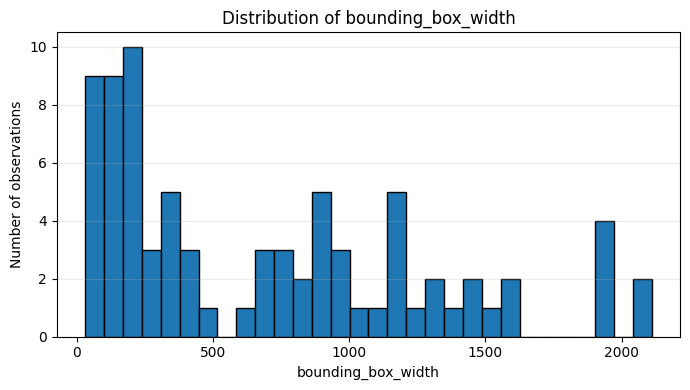

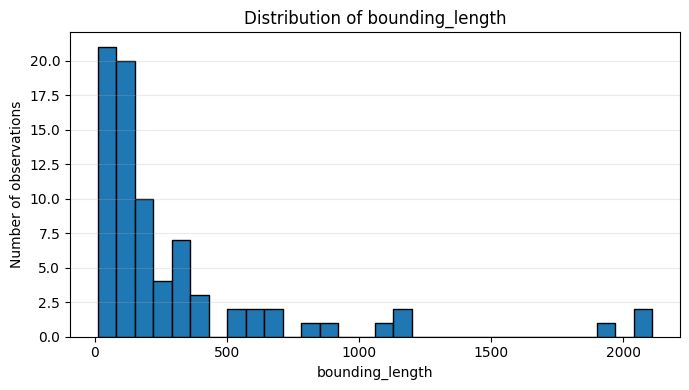

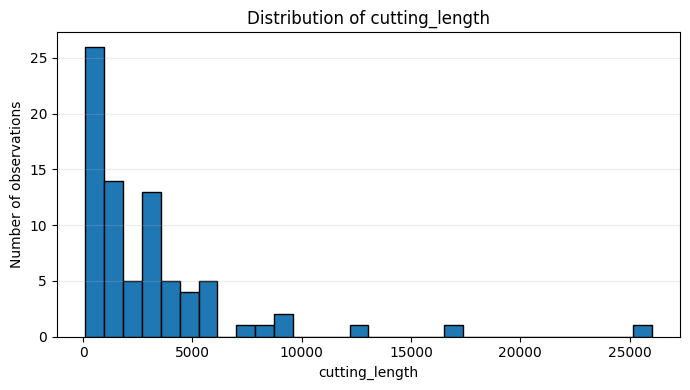

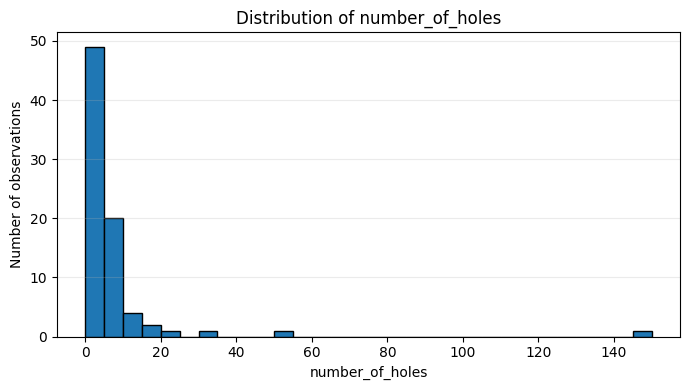

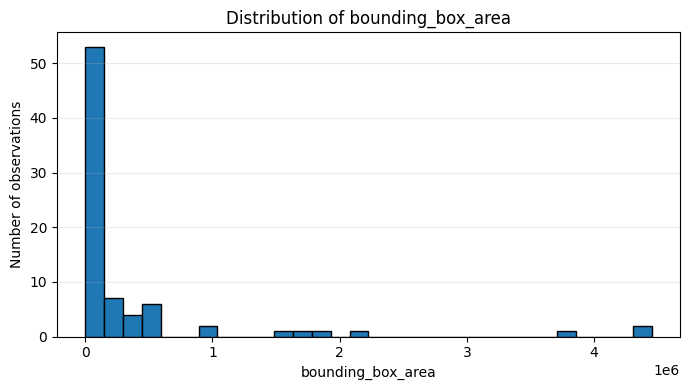

In [17]:
for feature in available_features:
    values = numeric_df[feature].dropna()
    if values.empty:
        continue
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(values, bins=30, edgecolor="black")
    ax.set(title=f"Distribution of {feature}", xlabel=feature, ylabel="Number of observations")
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

## 6. Boxplots and unusual observations

A boxplot summarizes the median and quartiles and highlights potential outliers.

The IQR rule flags values below `Q1 - 1.5 × IQR` or above `Q3 + 1.5 × IQR`.

**An outlier is not automatically an error.** A very large or intricate part may be a genuine product.

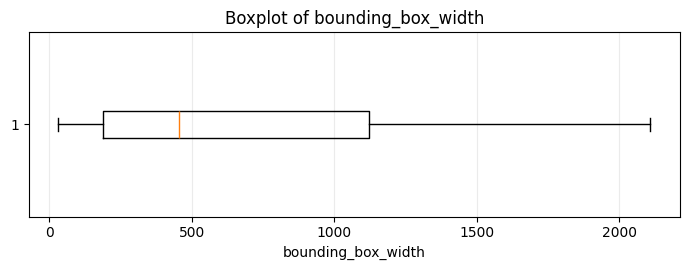

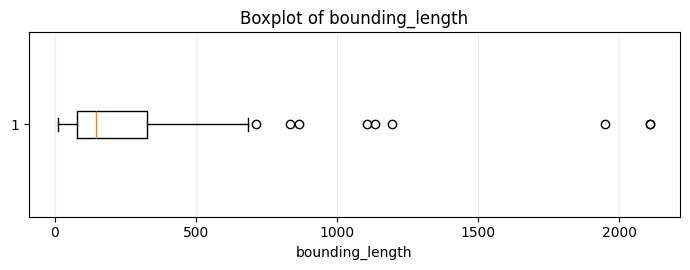

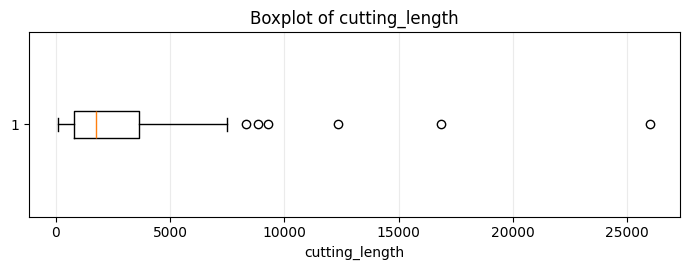

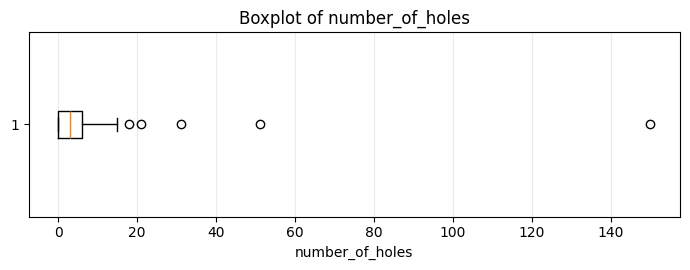

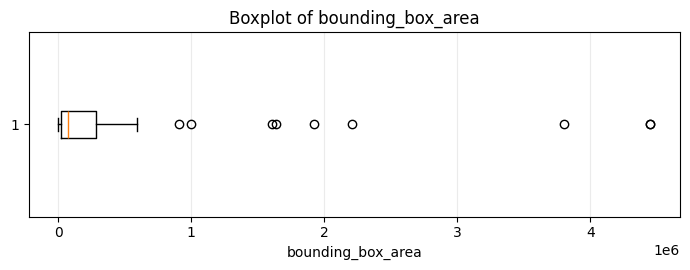

In [18]:
for feature in available_features:
    values = numeric_df[feature].dropna()
    if values.empty:
        continue
    fig, ax = plt.subplots(figsize=(7, 2.8))
    ax.boxplot(values, vert=False)
    ax.set(title=f"Boxplot of {feature}", xlabel=feature)
    ax.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    plt.show()

In the table below, the outliers are listed for each feature.The main idea is to calculate the first and third quantile (q1 and q3) and the interquartile range (iqr = q3 - q1). Then, we can define the lower and upper bounds for outliers as follows:
- Lower bound = q1 - 1.5 * iqr
- Upper bound = q3 + 1.5 * iqr   

The observations that fall outside are considered outliers. 

In the context of lasser cutting, these outliers may represent parts that are unusually large or complex, which could be of interest for further inspection. It is important to note that not all outliers are errors. Therefore is important to continue analysing these outliers in the following steps.

In [19]:
outlier_rows = []

for feature in available_features:
    values = numeric_df[feature].dropna()
    if values.empty:
        continue

    q1, q3 = values.quantile(0.25), values.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = numeric_df[feature].notna() & (
        (numeric_df[feature] < lower) | (numeric_df[feature] > upper)
    )

    for idx in df.index[mask]:
        row = {
            "row_index": idx,
            "feature": feature,
            "value": df.loc[idx, feature],
            "lower_bound": lower,
            "upper_bound": upper,
        }
        for id_col in ID_COLUMNS:
            if id_col in df.columns:
                row[id_col] = df.loc[idx, id_col]
        outlier_rows.append(row)

outliers = pd.DataFrame(outlier_rows)

if outliers.empty:
    print("No IQR outliers detected.")
else:
    display(
        outliers.sort_values(["feature", "value"], ascending=[True, False])
        .style.format(
            {"value": "{:,.2f}", "lower_bound": "{:,.2f}", "upper_bound": "{:,.2f}"}
        )
    )

,row_index,feature,value,lower_bound,upper_bound
20,0,bounding_box_area,"4,452,100.26","-376,149.86","681,118.92"
22,25,bounding_box_area,"4,452,100.00","-376,149.86","681,118.92"
21,16,bounding_box_area,"3,802,500.07","-376,149.86","681,118.92"
23,29,bounding_box_area,"2,209,629.28","-376,149.86","681,118.92"
25,48,bounding_box_area,"1,921,278.69","-376,149.86","681,118.92"
28,77,bounding_box_area,"1,638,981.75","-376,149.86","681,118.92"
26,51,bounding_box_area,"1,606,399.07","-376,149.86","681,118.92"
24,31,bounding_box_area,"996,411.32","-376,149.86","681,118.92"
27,65,bounding_box_area,"905,771.34","-376,149.86","681,118.92"
0,0,bounding_length,"2,110.00",-294.99,698.72


## 7. Relationships: correlation matrix

Pearson correlation measures the strength and direction of **linear** relationships.

- Near `+1`: strong positive linear association.
- Near `-1`: strong negative linear association.
- Near `0`: weak linear association.

Correlation does not prove causation and can miss nonlinear relationships. Extreme observations can influence it.

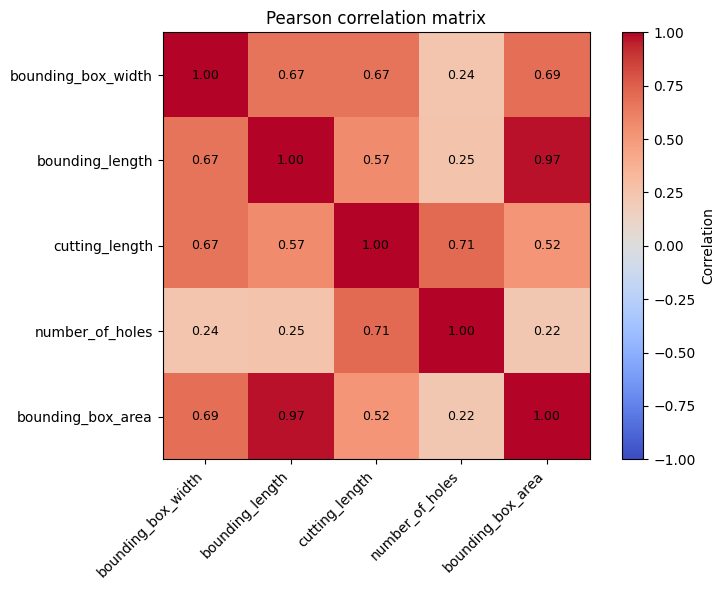

,bounding_box_width,bounding_length,cutting_length,number_of_holes,bounding_box_area
bounding_box_width,1.000,0.669,0.672,0.236,0.692
bounding_length,0.669,1.000,0.569,0.255,0.971
cutting_length,0.672,0.569,1.000,0.710,0.522
number_of_holes,0.236,0.255,0.710,1.000,0.221
bounding_box_area,0.692,0.971,0.522,0.221,1.000


In [20]:
correlation = numeric_df.corr(method="pearson")

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(correlation, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(correlation.columns)))
ax.set_yticks(range(len(correlation.index)))
ax.set_xticklabels(correlation.columns, rotation=45, ha="right")
ax.set_yticklabels(correlation.index)
ax.set_title("Pearson correlation matrix")

for i in range(len(correlation.index)):
    for j in range(len(correlation.columns)):
        value = correlation.iloc[i, j]
        if pd.notna(value):
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=9)

fig.colorbar(im, ax=ax, label="Correlation")
plt.tight_layout()
plt.show()
display(correlation.round(3))

## Interpretation:

Analyzing the correlation matrix the first couple that stands out is the number of holes and the cutting length, which have a correlation of 0.71. This is expected since the more holes a part has, the more cutting length is required to produce it. The second couple is the bundig_box_width and the bounding_length, wich have a correlation of 0.68. This is also expected since the larger the width of a piece, the larger the length is expected to be. The third couple is the bounding_box_area and the cutting_length, which have a correlation of 0.67. This is also expected since the larger the area of a piece, the more cutting length is required to produce since there are more area available to cut and more space to make holes. The last couple is the bounding_box_area and the number_of_holes, which have a correlation of 0.22. This is also expected since the larger the area of a piece, not necessary means that it will have more holes. The bounding_box_area and the bounding_box_length have a correlation of 0.97, wich is reasonale since the larger the piece the more area it will have, if the width is kept constant.

## 8. Scatterplots: investigate engineering questions

Recommended comparisons:

1. **Bounding box area vs. cutting length:** do larger envelopes tend to have longer cutting paths?
2. **Number of holes vs. cutting length:** do parts with more holes tend to have longer cutting paths?
3. **Width vs. height:** are parts concentrated around particular proportions?
4. **Bounding box area vs. number of holes:** are larger parts also more perforated?

Look for trends, clusters, curved patterns and isolated points. A trend is an association, not proof of causation.

,customer_name,customer_branch,file_name,order_quantity,possible_duplicate,bounding_box_width,bounding_length,cutting_length,number_of_holes,bounding_box_area
0,MetalForm SA,Frankfurt Branch,Geo (1).DXF,1600,False,2110.000062,2110.000062,3438.024977,0.0,4.452100e+06
16,MetalForm SA,Frankfurt Branch,Geo (25).DXF,1100,False,1950.000009,1950.000029,12326.862958,5.0,3.802500e+06
25,MetalForm SA,Frankfurt Branch,Geo (33).DXF,850,False,2110.000000,2110.000000,3625.275477,3.0,4.452100e+06
29,MetalForm SA,Frankfurt Branch,Geo (37).DXF,1800,False,1947.204525,1134.770001,8330.442132,31.0,2.209629e+06
31,MetalForm SA,Frankfurt Branch,Geo (39).DXF,1250,False,1400.631661,711.401400,6059.394370,18.0,9.964113e+05
39,AutoParts AG,Berlin Branch,Geo (47).DXF,7900,False,900.572159,90.963841,2776.804983,21.0,8.191950e+04
48,MetalForm SA,Frankfurt Branch,Geo (54).DXF,1050,False,1610.107161,1193.261380,26007.870470,150.0,1.921279e+06
51,MetalForm SA,Frankfurt Branch,Geo (57).DXF,500,False,1453.993892,1104.818309,9286.051115,6.0,1.606399e+06
59,AutoParts AG,Munich Branch,Geo (64).DXF,8650,False,899.317895,628.570597,8862.895041,8.0,5.652848e+05
65,MetalForm SA,Frankfurt Branch,Geo (69).DXF,1100,False,1047.443056,864.745182,3847.894165,0.0,9.057713e+05


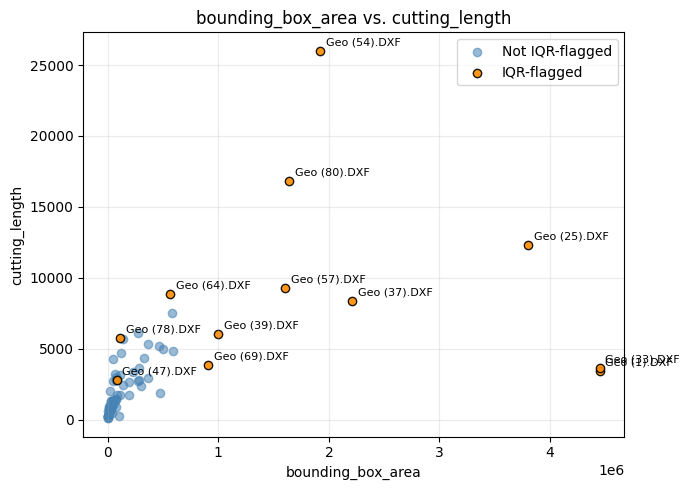

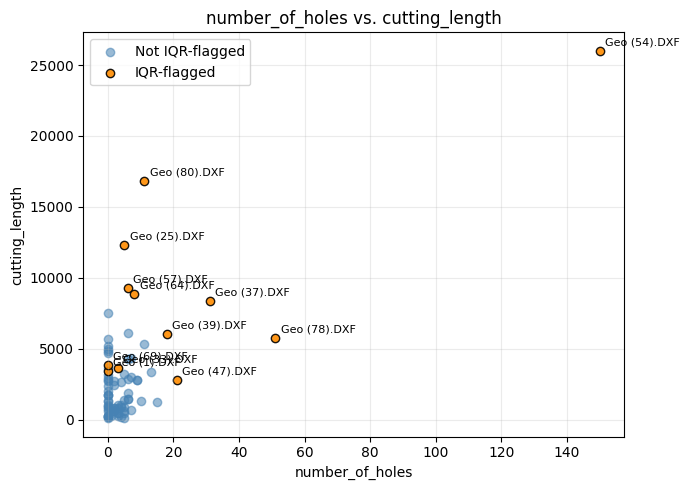

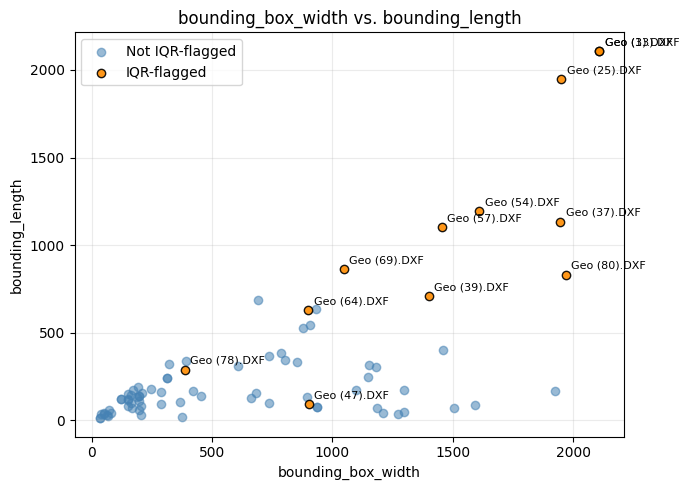

In [21]:
# Show all available columns for rows flagged in the previous outlier list
outlier_indices_for_review = sorted(outliers["row_index"].unique())

if outlier_indices_for_review:
    display(df.loc[outlier_indices_for_review].sort_index())
else:
    print("No IQR-flagged rows to review.")

# Plot selected feature relationships, highlighting any IQR-flagged rows
flagged_mask = df.index.isin(outlier_indices_for_review)
review_pairs = [
    ("bounding_box_area", "cutting_length"),
    ("number_of_holes", "cutting_length"),
    ("bounding_box_width", "bounding_length"),
]

label_column = next(
    (col for col in ["file_name", "filename"] if col in df.columns),
    None
)

for x_col, y_col in review_pairs:
    if x_col not in df.columns or y_col not in df.columns:
        print(f"Skipping {x_col} vs. {y_col}: column missing.")
        continue

    plot_data = df[[x_col, y_col]].apply(pd.to_numeric, errors="coerce")
    valid = plot_data.notna().all(axis=1)
    regular = valid & ~flagged_mask
    flagged = valid & flagged_mask

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(
        plot_data.loc[regular, x_col], plot_data.loc[regular, y_col],
        alpha=0.55, color="steelblue", label="Not IQR-flagged"
    )
    ax.scatter(
        plot_data.loc[flagged, x_col], plot_data.loc[flagged, y_col],
        alpha=0.9, color="darkorange", edgecolor="black",
        label="IQR-flagged"
    )

    if label_column:
        for row_idx in plot_data.index[flagged]:
            ax.annotate(
                str(df.loc[row_idx, label_column]),
                (plot_data.loc[row_idx, x_col], plot_data.loc[row_idx, y_col]),
                xytext=(4, 4), textcoords="offset points", fontsize=8
            )

    ax.set(title=f"{x_col} vs. {y_col}", xlabel=x_col, ylabel=y_col)
    ax.grid(alpha=0.25)
    ax.legend()
    plt.tight_layout()
    plt.show()

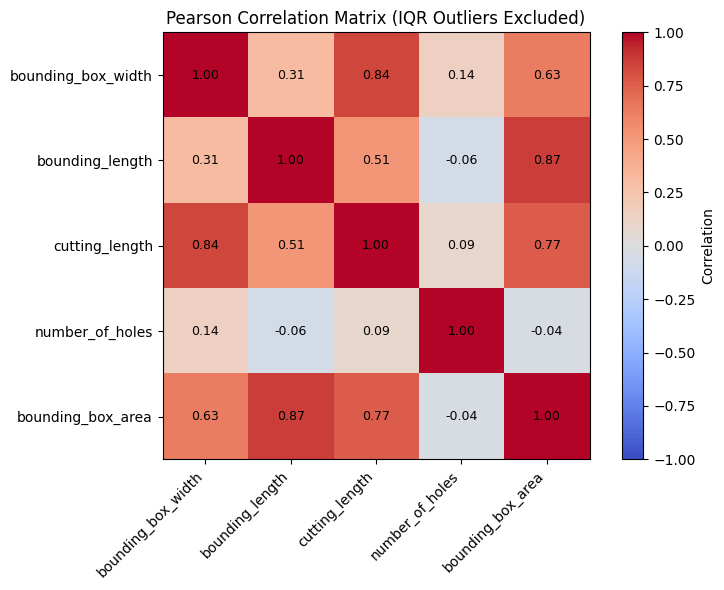

,bounding_box_width,bounding_length,cutting_length,number_of_holes,bounding_box_area
bounding_box_width,1.000,0.307,0.839,0.141,0.629
bounding_length,0.307,1.000,0.513,-0.064,0.874
cutting_length,0.839,0.513,1.000,0.087,0.765
number_of_holes,0.141,-0.064,0.087,1.000,-0.042
bounding_box_area,0.629,0.874,0.765,-0.042,1.000


Excluded 12 rows; 67 rows remain.


In [38]:
outlier_indices = outliers["row_index"].unique() if not outliers.empty else []
numeric_inliers = numeric_df.loc[~numeric_df.index.isin(outlier_indices)]

correlation_without_outliers = numeric_inliers.corr(method="pearson")

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(correlation_without_outliers, vmin=-1, vmax=1, cmap="coolwarm")

ax.set_xticks(range(len(correlation_without_outliers.columns)))
ax.set_yticks(range(len(correlation_without_outliers.index)))
ax.set_xticklabels(correlation_without_outliers.columns, rotation=45, ha="right")
ax.set_yticklabels(correlation_without_outliers.index)
ax.set_title("Pearson Correlation Matrix (IQR Outliers Excluded)")

for i in range(len(correlation_without_outliers.index)):
    for j in range(len(correlation_without_outliers.columns)):
        value = correlation_without_outliers.iloc[i, j]
        if pd.notna(value):
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=9)

fig.colorbar(im, ax=ax, label="Correlation")
plt.tight_layout()
plt.show()

display(correlation_without_outliers.round(3))
print(f"Excluded {len(outlier_indices)} rows; {len(numeric_inliers)} rows remain.")

## finding 2 cutting lenth and bounding box area.


Excluded 10 outlier rows.


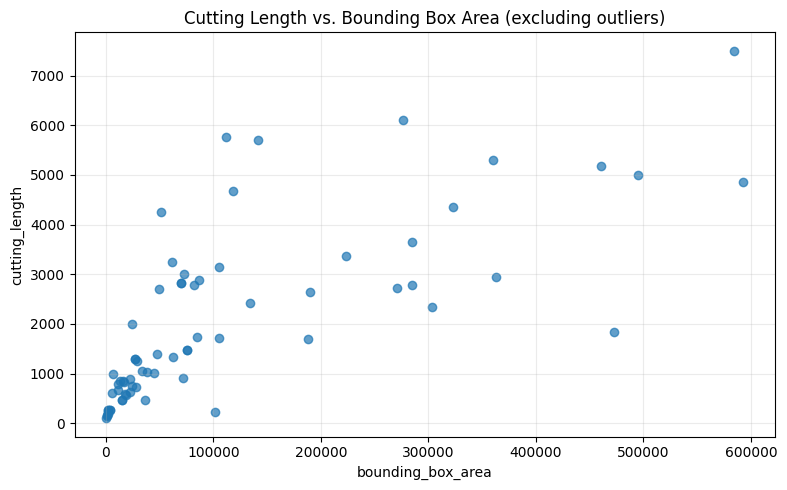

In [28]:
# Exclude rows flagged as IQR outliers in either plotted feature
x_col, y_col = "bounding_box_area", "cutting_length"
scatter_df = numeric_df[[x_col, y_col]].dropna().copy()

inliers = pd.Series(True, index=scatter_df.index)
for feature in [x_col, y_col]:
    q1 = scatter_df[feature].quantile(0.25)
    q3 = scatter_df[feature].quantile(0.75)
    iqr = q3 - q1
    inliers &= scatter_df[feature].between(q1 - 1.5 * iqr, q3 + 1.5 * iqr)

print(f"Excluded {len(scatter_df) - inliers.sum()} outlier rows.")

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(scatter_df.loc[inliers, x_col], scatter_df.loc[inliers, y_col], alpha=0.7)
ax.set(
    title="Cutting Length vs. Bounding Box Area (excluding outliers)",
    xlabel=x_col,
    ylabel=y_col,
)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

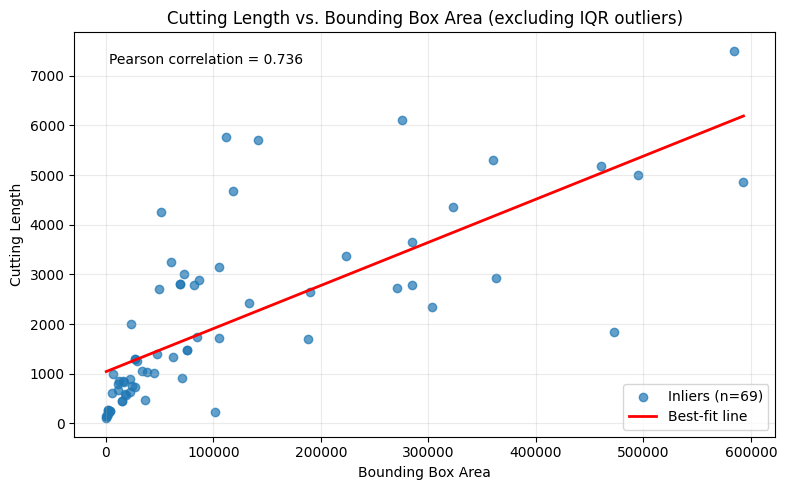

Pearson correlation coefficient (inliers): 0.736


In [29]:
# Use the inlier data prepared in the previous cell
fit_data = scatter_df.loc[inliers]
x = fit_data["bounding_box_area"]
y = fit_data["cutting_length"]

if len(fit_data) < 2:
    raise ValueError("At least two inlier observations are needed to fit a line.")

slope, intercept = np.polyfit(x, y, 1)
correlation_coefficient = x.corr(y)

x_line = np.linspace(x.min(), x.max(), 200)
y_line = slope * x_line + intercept

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y, alpha=0.7, label=f"Inliers (n={len(fit_data)})")
ax.plot(x_line, y_line, color="red", linewidth=2, label="Best-fit line")

ax.set(
    title="Cutting Length vs. Bounding Box Area (excluding IQR outliers)",
    xlabel="Bounding Box Area",
    ylabel="Cutting Length",
)
ax.text(
    0.05, 0.95,
    f"Pearson correlation = {correlation_coefficient:.3f}",
    transform=ax.transAxes,
    va="top",
)
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

print(f"Pearson correlation coefficient (inliers): {correlation_coefficient:.3f}")

## Interpretation:

On this scatterplots the data is evaluated to see if there are any trends, relationships between two feaatures. Also the orange observations are the outliers that we previously identified. The first scatterplot is about the bounding box area and the cutting length and it can be seen that in the right side there are datapoints spread around, this demostrate that there is not a visual correlation between them. The second plot is about the number of holes an the cutting length wich most of the points are concentrated on the left side of the plot, this is a sing of a pattern. This means that the mean and meadian will go around 10 holes and 5000 mm, and future sells might expected around that area(these specific number of holes and cutting length). The third plot is about bounding box width and bounding box length, and it can be seen that the points are concentrated around a line, this is a sign of a pattern. This means that the data follows a linear relationship, and future sells might be expected around that line. 

## finding 1 number of holes and cutting length.

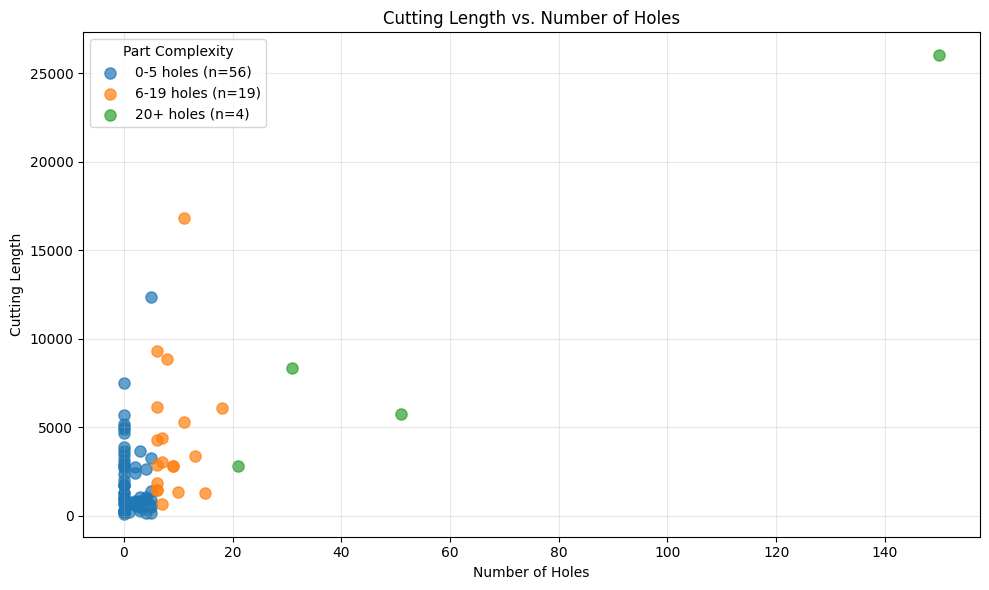

In [26]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Prepare data
# --------------------------------------------------

plot_df = df[["number_of_holes", "cutting_length"]].copy()

plot_df["number_of_holes"] = pd.to_numeric(
    plot_df["number_of_holes"], errors="coerce"
)

plot_df["cutting_length"] = pd.to_numeric(
    plot_df["cutting_length"], errors="coerce"
)

plot_df = plot_df.dropna()

# --------------------------------------------------
# 2. Create groups
# --------------------------------------------------

plot_df["hole_group"] = np.select(
    [
        plot_df["number_of_holes"].between(0, 5),
        plot_df["number_of_holes"].between(6, 19),
        plot_df["number_of_holes"] >= 20
    ],
    [
        "0-5 holes",
        "6-19 holes",
        "20+ holes"
    ],
    default="Other"
)

# --------------------------------------------------
# 3. Scatterplot
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))

groups = ["0-5 holes", "6-19 holes", "20+ holes"]

for group in groups:
    subset = plot_df[plot_df["hole_group"] == group]

    ax.scatter(
        subset["number_of_holes"],
        subset["cutting_length"],
        label=f"{group} (n={len(subset)})",
        alpha=0.7,
        s=65
    )

ax.set_title("Cutting Length vs. Number of Holes")
ax.set_xlabel("Number of Holes")
ax.set_ylabel("Cutting Length")
ax.legend(title="Part Complexity")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [27]:

# Mean cutting length by number of holes

plot_df["hole_group"] = np.select(
    [
        plot_df["number_of_holes"].between(0, 5),
        plot_df["number_of_holes"].between(6, 19),
        plot_df["number_of_holes"] >= 20
    ],
    ["0-5 holes", "6-19 holes", "20+ holes"],
    default="Other"
)

mean_by_group = (
    plot_df.groupby("hole_group")["cutting_length"]
    .agg(["count", "mean", "median"])
    .reindex(["0-5 holes", "6-19 holes", "20+ holes"])
)

print(mean_by_group.round(2))


            count      mean   median
hole_group                          
0-5 holes      56   2010.95  1045.41
6-19 holes     19   4421.71  3011.77
20+ holes       4  10718.17  7043.99


## finding 3

## 9. Retrieve the unusual rows for DXF inspection

For each unusual row:

1. Find its filename or part identifier.
2. Open the corresponding DXF.
3. Check whether the unusual value reflects a genuine design (large envelope, long contour, many internal features).
4. Check for extraction/data issues (wrong units, duplicate geometry, unsupported DXF entities).

In [22]:
if not outliers.empty:
    unusual_indices = sorted(outliers["row_index"].unique())
    columns_to_show = [c for c in ID_COLUMNS + available_features if c in df.columns]
    display(df.loc[unusual_indices, columns_to_show])
else:
    print("There are no IQR-flagged rows to display.")

,bounding_box_width,bounding_length,cutting_length,number_of_holes,bounding_box_area
0,2110.000062,2110.000062,3438.024977,0.0,4.452100e+06
16,1950.000009,1950.000029,12326.862958,5.0,3.802500e+06
25,2110.000000,2110.000000,3625.275477,3.0,4.452100e+06
29,1947.204525,1134.770001,8330.442132,31.0,2.209629e+06
31,1400.631661,711.401400,6059.394370,18.0,9.964113e+05
39,900.572159,90.963841,2776.804983,21.0,8.191950e+04
48,1610.107161,1193.261380,26007.870470,150.0,1.921279e+06
51,1453.993892,1104.818309,9286.051115,6.0,1.606399e+06
59,899.317895,628.570597,8862.895041,8.0,5.652848e+05
65,1047.443056,864.745182,3847.894165,0.0,9.057713e+05


## 10. Findings and interpretation — complete after running the notebook

Use your actual outputs to answer:

### Distributions
- Which feature has the largest spread?
- Which features are skewed?
- Are there multiple clusters or peaks?

### Relationships
- Which pairs have the strongest correlations?
- Does bounding box area appear related to cutting length?
- Does hole count appear related to cutting length?
- Do scatterplots reveal clusters or nonlinear patterns?

### Unusual observations
- Which parts are flagged by the IQR rule?
- Are they genuine designs or possible data/extraction errors?
- What do their DXF drawings show?

### Manufacturing interpretation
- Cutting length can approximate laser travel distance, but is not a direct measure of cutting time.
- Hole count may indicate internal contours and piercing operations, depending on how holes are defined and detected.
- Bounding box dimensions describe the overall envelope, not actual material area or retrieval difficulty.
- Small or intricate parts may be difficult to retrieve even if their cutting length is not especially high.

### Limitations
Mention factors not represented by these geometric features, such as material, thickness, cutting speed, machine settings, piercing time, sheet layout/nesting and physical handling.

**Do not write conclusions before inspecting your actual outputs.** The notebook provides evidence; your interpretation should describe what that evidence supports.